In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, bilinear, freqz, cheby1

In [21]:
def design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency):

    analog_b, analog_a = butter(filter_order, cutoff_frequency, analog=True, btype='low')
    print("analog_b:", analog_b)
    print("analog_a:", analog_a)

    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    
    return digital_b, digital_a


In [34]:
filter_order = 4
cutoff_frequency = 6000 
sampling_frequency = 8000
ripple = 0.5


In [ ]:
digital_b,digital_a =design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency)
print("digital_b:", digital_b)
print("digital_a:", digital_a)

analog_b: [1.296e+15]
analog_a: [1.00000000e+00 1.56787556e+04 1.22911688e+08 5.64435201e+11
 1.29600000e+15]
digital_b: [0.00755471 0.03021885 0.04532828 0.03021885 0.00755471]
digital_a: [ 1.         -2.14130906  1.97064469 -0.85446115  0.14600093]


Text(0, 0.5, 'Magnitude')

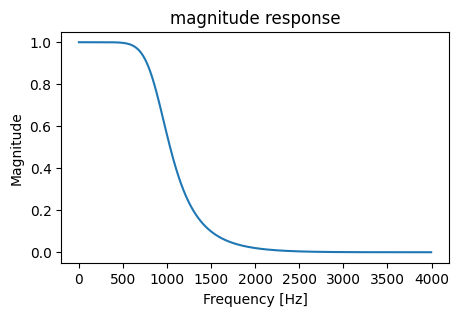

In [36]:
frequency, magnitude_response = freqz(digital_b,digital_a,fs=sampling_frequency,worN=1024)
plt.figure(figsize=(5, 3))
plt.plot(frequency,np.abs(magnitude_response))
plt.title('magnitude response')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')


c:\Users\swethan sandhi\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\swethan sandhi\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Text(0, 0.5, 'Magnitude')

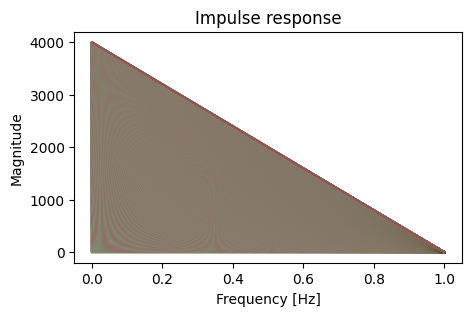

In [37]:
impulse_response = freqz(digital_b, digital_a,  fs=sampling_frequency,worN=4096)
plt.figure(figsize=(5, 3)) 
plt.plot(impulse_response)
plt.title('Impulse response')   
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude') 

In [33]:
def design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple):
    analog_b, analog_a = cheby1(filter_order, ripple, cutoff_frequency, analog=True, btype='low')
    print("analog_b:", analog_b)
    print("analog_a:", analog_a)
    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    return digital_b, digital_a

In [38]:
digital_b,digital_a =design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple)
print("digital_b:", digital_b)
print("digital_a:", digital_a)

analog_b: [4.63769576e+14]
analog_a: [1.00000000e+00 7.18431394e+03 6.18071834e+07 2.21498340e+11
 4.91249651e+14]
digital_b: [0.00403907 0.01615629 0.02423443 0.01615629 0.00403907]
digital_a: [ 1.         -2.71679802  3.17467029 -1.81511561  0.42569778]


Text(0, 0.5, 'Magnitude')

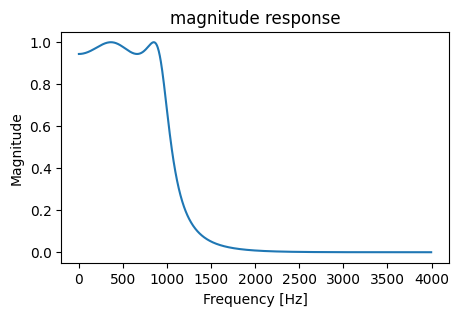

In [39]:
frequency, magnitude_response = freqz(digital_b,digital_a,fs=sampling_frequency,worN=1024)
plt.figure(figsize=(5, 3))
plt.plot(frequency,np.abs(magnitude_response))
plt.title('magnitude response')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')

Text(0, 0.5, 'Magnitude')

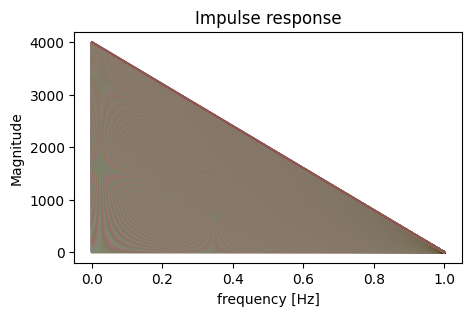

In [43]:
impulse_response = freqz(digital_b, digital_a,  fs=sampling_frequency,worN=4096)
plt.figure(figsize=(5, 3)) 
plt.plot(impulse_response)
plt.title('Impulse response')   
plt.xlabel('frequency [Hz]')
plt.ylabel('Magnitude')